### Random Forests and Photo-zs

En este notebook, se usa el algoritmo de random forest para estimar redshifts fotométricos a partir de observaciones de galaxias en 6 filtros diferentes  (u, g, r, i, z, y).

Basado en Machine learning for physics and Astronomy, Viviana Acquaviva (2023)

Trataremos de reproducir los resultados de [Zhou et. al. 2019](https://academic.oup.com/mnras/article/488/4/4565/5538813)

In [6]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)


font = {'size'   : 16}
matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=14) 
matplotlib.rc('ytick', labelsize=14) 
matplotlib.rcParams.update({'figure.autolayout': False})
matplotlib.rcParams['figure.dpi'] = 300

In [7]:
from sklearn import metrics
from sklearn.model_selection import cross_validate, KFold, cross_val_predict, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

In [8]:
#!pip install astropy
import astropy

from astropy.io import fits


#### Importamos los datos

Leemos el archivo fits y lo leemos usando pandas

In [ ]:

#with fits.open('DEEP2_uniq_Terapix_Subaru_v1.fits') as data:
#    df = pd.DataFrame(np.array(data[1].data).byteswap().newbyteorder()) 
    #https://numpy.org/doc/2.1/user/byteswapping.html

'''
Esto soltaba un error:

---------------------------------------------------------------------------
AttributeError                            Traceback (most recent call last)
Cell In[14], line 2
      1 with fits.open('DEEP2_uniq_Terapix_Subaru_v1.fits') as data:
----> 2     df = pd.DataFrame(np.array(data[1].data).byteswap().newbyteorder()) 
      3     #https://numpy.org/doc/2.1/user/byteswapping.html

AttributeError: 'numpy.ndarray' object has no attribute 'newbyteorder'

Se hizo el reemplazo por lo siguiente: (me ayudó Claude)
'''

from astropy.table import Table
df = Table.read('DEEP2_uniq_Terapix_Subaru_v1.fits').to_pandas()

In [ ]:
df.columns

Index(['objno_deep2', 'ra_deep2', 'dec_deep2', 'magb', 'magr', 'magi', 'pgal',
       'sfd_ebv', 'class', 'subclass', 'objname', 'maskname', 'slitname',
       'date', 'mjd', 'z_raw', 'zhelio', 'z_err', 'rchi2', 'dof', 'vdisp',
       'vdisp_err', 'zquality', 'egsflags', 'comment', 'm_b', 'ub_0',
       'ra_cfhtls', 'dec_cfhtls', 'u', 'g', 'r', 'i', 'i2', 'z', 'uerr',
       'gerr', 'rerr', 'ierr', 'i2err', 'zerr', 'u_apercor', 'g_apercor',
       'r_apercor', 'i_apercor', 'i2_apercor', 'z_apercor', 'uerr_aper',
       'gerr_aper', 'rerr_aper', 'ierr_aper', 'i2err_aper', 'zerr_aper',
       'uerr_apercor', 'gerr_apercor', 'rerr_apercor', 'ierr_apercor',
       'i2err_apercor', 'zerr_apercor', 'r_radius_arcsec', 'u(sexflag)',
       'g(sexflag)', 'r(sexflag)', 'i(sexflag)', 'i2(sexflag)', 'z(sexflag)',
       'flag_cfhtls', 'cfhtls_source', 'ra_subaru', 'dec_subaru', 'y', 'yerr',
       'y_apercor', 'yerr_aper', 'yerr_apercor', 'y(sexflag)',
       'y_radius_arcsec', 'subaru_source'],
 

In [11]:
df.head()

,objno_deep2,ra_deep2,dec_deep2,magb,magr,magi,pgal,sfd_ebv,class,subclass,objname,maskname,slitname,date,mjd,z_raw,zhelio,z_err,rchi2,dof,vdisp,vdisp_err,zquality,egsflags,comment,m_b,ub_0,ra_cfhtls,dec_cfhtls,u,g,r,i,i2,z,uerr,gerr,rerr,ierr,i2err,zerr,u_apercor,g_apercor,r_apercor,i_apercor,i2_apercor,z_apercor,uerr_aper,gerr_aper,rerr_aper,ierr_aper,i2err_aper,zerr_aper,uerr_apercor,gerr_apercor,rerr_apercor,ierr_apercor,i2err_apercor,zerr_apercor,r_radius_arcsec,u(sexflag),g(sexflag),r(sexflag),i(sexflag),i2(sexflag),z(sexflag),flag_cfhtls,cfhtls_source,ra_subaru,dec_subaru,y,yerr,y_apercor,yerr_aper,yerr_apercor,y(sexflag),y_radius_arcsec,subaru_source
0,11001673,213.868704,51.956445,23.487745,23.143082,22.582092,1.000000,0.010943,NaN,NaN,b'11001673',b'1101',b'000',b'2003-05-06',52765.457031,1.115297,1.115261,999.900024,0.630934,57.0,999.900024,999.900024,2,16777216,"b'bext, bcol, possible OII'",-999.000000,-999.0000,213.868620,51.956434,23.529039,23.393115,23.148170,22.854212,-99.0,22.162377,0.0678,0.0400,0.0382,0.0678,-99.0,0.0623,23.543491,23.430495,23.100311,22.768970,-99.0,22.223810,0.0542,0.0323,0.0279,0.0466,-99.0,0.0536,0.039631,0.041359,0.039777,0.046863,-99.0,0.043833,0.581804,3,3,3,3,-99,3,0,1,213.868626,51.956443,21.869627,0.060918,21.926356,0.041955,0.141778,3.0,0.656514,1
1,11001699,213.810471,51.942316,22.067692,20.034674,19.545080,3.000000,0.011014,b'GALAXY',NaN,b'11001699',b'1100',b'7',b'2003-05-03',52762.441406,0.290641,0.290608,0.000043,1.178153,5901.0,166.334991,49.481255,4,16777216,NaN,-19.228701,1.1295,213.810138,51.942348,30.123756,28.298480,18.540350,99.000000,-99.0,99.000000,0.0000,0.0000,0.0014,99.0000,-99.0,99.0000,30.848978,28.989668,19.027422,99.000000,-99.0,99.000000,0.0000,0.0000,0.0028,99.0000,-99.0,99.0000,0.029567,0.030353,0.027558,99.000000,-99.0,99.000000,0.824625,19,19,19,3,-99,3,244,1,213.810455,51.942321,18.757229,0.005813,18.811085,0.004386,0.050987,3.0,0.744269,1
2,11001770,213.848431,51.948876,24.144438,24.103180,24.020006,3.000000,0.010856,b'GALAXY',NaN,b'11001770',b'1101',b'003',b'2003-05-06',52765.457031,0.605779,0.605744,-5.000000,1.047260,5318.0,184.860001,195.000000,1,16777216,NaN,-999.000000,-999.0000,213.848409,51.948865,24.294289,24.399293,24.413366,23.398456,-99.0,24.157690,0.1646,0.1383,0.2306,0.1867,-99.0,0.4558,24.324670,24.273606,24.150319,23.446252,-99.0,23.574236,0.1146,0.0870,0.1242,0.1309,-99.0,0.1793,0.111127,0.130134,0.123620,0.117813,-99.0,0.101059,0.728119,0,0,0,0,-99,0,0,1,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.0,-99.000000,-99
3,11001800,213.831758,51.952548,25.336836,23.508480,23.081087,0.509809,0.010823,b'GALAXY',NaN,b'11001800',b'1100',b'004',b'2003-05-03',52762.441406,1.306830,1.306796,-5.000000,1.014062,5788.0,0.000000,0.000000,1,16777216,NaN,-999.000000,-999.0000,213.831785,51.952539,26.363821,24.530998,23.559140,23.065110,-99.0,22.737333,0.9609,0.1344,0.0648,0.0997,-99.0,0.1110,99.000000,24.804309,23.636544,23.009222,-99.0,22.689591,99.0000,0.1077,0.0426,0.0568,-99.0,0.0661,99.000000,0.046521,0.041142,0.054297,-99.0,0.053818,0.549061,0,0,0,0,-99,0,0,1,213.831766,51.952544,22.404269,0.088970,22.535600,0.053497,0.094733,0.0,0.455820,1
4,11001860,213.832550,51.954174,24.382738,23.401484,22.572845,3.000000,0.010827,b'GALAXY',NaN,b'11001860',b'1101',b'10',b'2003-05-06',52765.457031,0.957705,0.957669,0.000099,1.039979,5952.0,109.394997,17.208755,4,16777216,NaN,-20.083200,0.7524,213.832540,51.954167,24.571406,24.023086,23.493832,22.691404,-99.0,22.387428,0.1924,0.0874,0.0651,0.0715,-99.0,0.0850,24.362068,24.136913,23.490342,22.777181,-99.0,22.319676,0.1002,0.0615,0.0420,0.0473,-99.0,0.0508,0.050326,0.053198,0.052364,0.058492,-99.0,0.053587,0.595684,0,0,0,0,-99,0,0,1,213.832574,51.954175,22.242717,0.070760,22.100980,0.033256,0.073067,0.0,0.442022,1


In [12]:
df.shape

(23822, 78)

Seleccione las columnas que contienen el brillo de las galaxias en los 6 filtros de interés, 'u,g,r,i,z,y' (con sufijo 'apercor') como las características y el redshift (espectroscópico) como la variable a predecir (`zhelio`)

In [16]:
features = df[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor', 'y_apercor']]

In [17]:
target = df['zhelio']

In [18]:
features.describe()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor
count,23822.000000,23822.000000,23822.000000,23822.000000,23822.000000,23822.000000
mean,23.030009,22.054381,21.459569,21.018872,20.791391,-36.894099
std,21.661775,20.858882,20.795278,20.786143,20.782124,60.688602
min,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000
25%,23.673291,23.239957,22.596881,22.013467,21.711539,-99.000000
50%,24.320863,23.911515,23.414908,22.911102,22.629739,19.360840
75%,25.003412,24.437682,23.893222,23.495253,23.288285,22.468418
max,99.000000,99.000000,99.000000,99.000000,99.000000,99.000000


In [19]:
target.describe()

count    23822.000000
mean         0.714948
std          0.417605
min         -0.078525
25%          0.393856
50%          0.688211
75%          0.983307
max          4.500611
Name: zhelio, dtype: float64

### Ahora empezaremos a implementar nuestro modelo de Random Forest

Figura 5 del paper

 ![Performance of photometric redshift reconstruction](https://oup.silverchair-cdn.com/oup/backfile/Content_public/Journal/mnras/488/4/10.1093_mnras_stz1866/1/stz1866fig5.jpeg?Expires=1764255560&Signature=YsogBmQvQ0CkbNXBEimFc23Rt9Slq~Q5qJGdV1YfvS3w-Z3IEJvD7FrYcOoSm6U0xY-gU~5JqYe2A7wjaHjQ~GAPOIZP8Kod-zh~1sxPBUDM3aj4kio313nsCcC-zCJRDd1OEvPncis9N7puYcPeqj2R3rSNaGk4QJCOBtGhE5-NLbwFbQFalDhy7dELFeMm4uZQxaCwNeJF1NsQBETobU-LK13KulZ51tMrLF1HiDEjQetQBvccYAG6sC2fTWrNNtv9lSl9PEaac9qHSycwfyDc8GeHPFyh~DmL7KSQM3V1PEEkjG6-RYrwZaXYBorj5PkR9ZLJQzoNqRxn4Gl7rg__&Key-Pair-Id=APKAIE5G5CRDK6RD3PGA)

En la figura, $\sigma_{NMAD}$ es la [normalized median absolute deviation de los residuos](https://en.wikipedia.org/wiki/Median_absolute_deviation), definida como $\sigma_{NMAD}=1.48\cdot MAD$, donde $MAD = \text{median}(\frac{|\Delta z|}{(1 + zspec)})$, $\Delta z =z_{phot}-z_{spec}$  y $\eta$ es la fracción de outliers definido como los objetos que cumplen $|(\Delta z)| > 0.15\cdot(1+z_{spec})$



In [20]:
model = RandomForestRegressor()

In [21]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Empezaremos estableciendo un benchmark

Implemente el modelo de random forest definido arriba en esquema de validación cruzada KFold, reporte la métrica para entrenamiento y prueba. Recordemos que la métrica por defecto es $R^2$

In [22]:
%%time
cv = KFold(n_splits=5, shuffle=True, random_state=10)
scores = cross_validate(model, features, target, cv=cv, return_train_score=True, n_jobs=-1)

CPU times: user 134 ms, sys: 39.9 ms, total: 174 ms
Wall time: 18.2 s


In [23]:
scores

{'fit_time': array([10.54330325, 10.64815474, 10.51467395, 10.6205678 , 13.92635274]),
 'score_time': array([0.17334414, 0.15412569, 0.15293026, 0.15546846, 0.15202165]),
 'test_score': array([0.30271756, 0.30710683, 0.31372219, 0.30754555, 0.31297862]),
 'train_score': array([0.87341641, 0.87848969, 0.87728403, 0.87613254, 0.87328016])}

Calcule el promedio y la desviación estándar de las métricas obtenidas.

In [24]:
print('Train R2: %.3f ± %.3f' % (scores['train_score'].mean(), scores['train_score'].std()))

Train R2: 0.876 ± 0.002


In [25]:
print('Test R2: %.3f ± %.3f' % (scores['test_score'].mean(), scores['test_score'].std()))

Test R2: 0.309 ± 0.004


**Qué puede decir de este resultado? Hay bias alto o varianza alta?**

R: Hay varianza alta, el R2 del entrenamiento es más alto que el de prueba por lo que el modelo se está overfitteando. Osea que se está memorizando el set de entramiento y no está generalizando bien. 

Puede comparar los valores reales con los predichos, generando las predicciones con `cross_val_predict`

In [26]:
ypred = cross_val_predict(model, features, target, cv=cv, n_jobs=-1)

(0.0, 3.0)

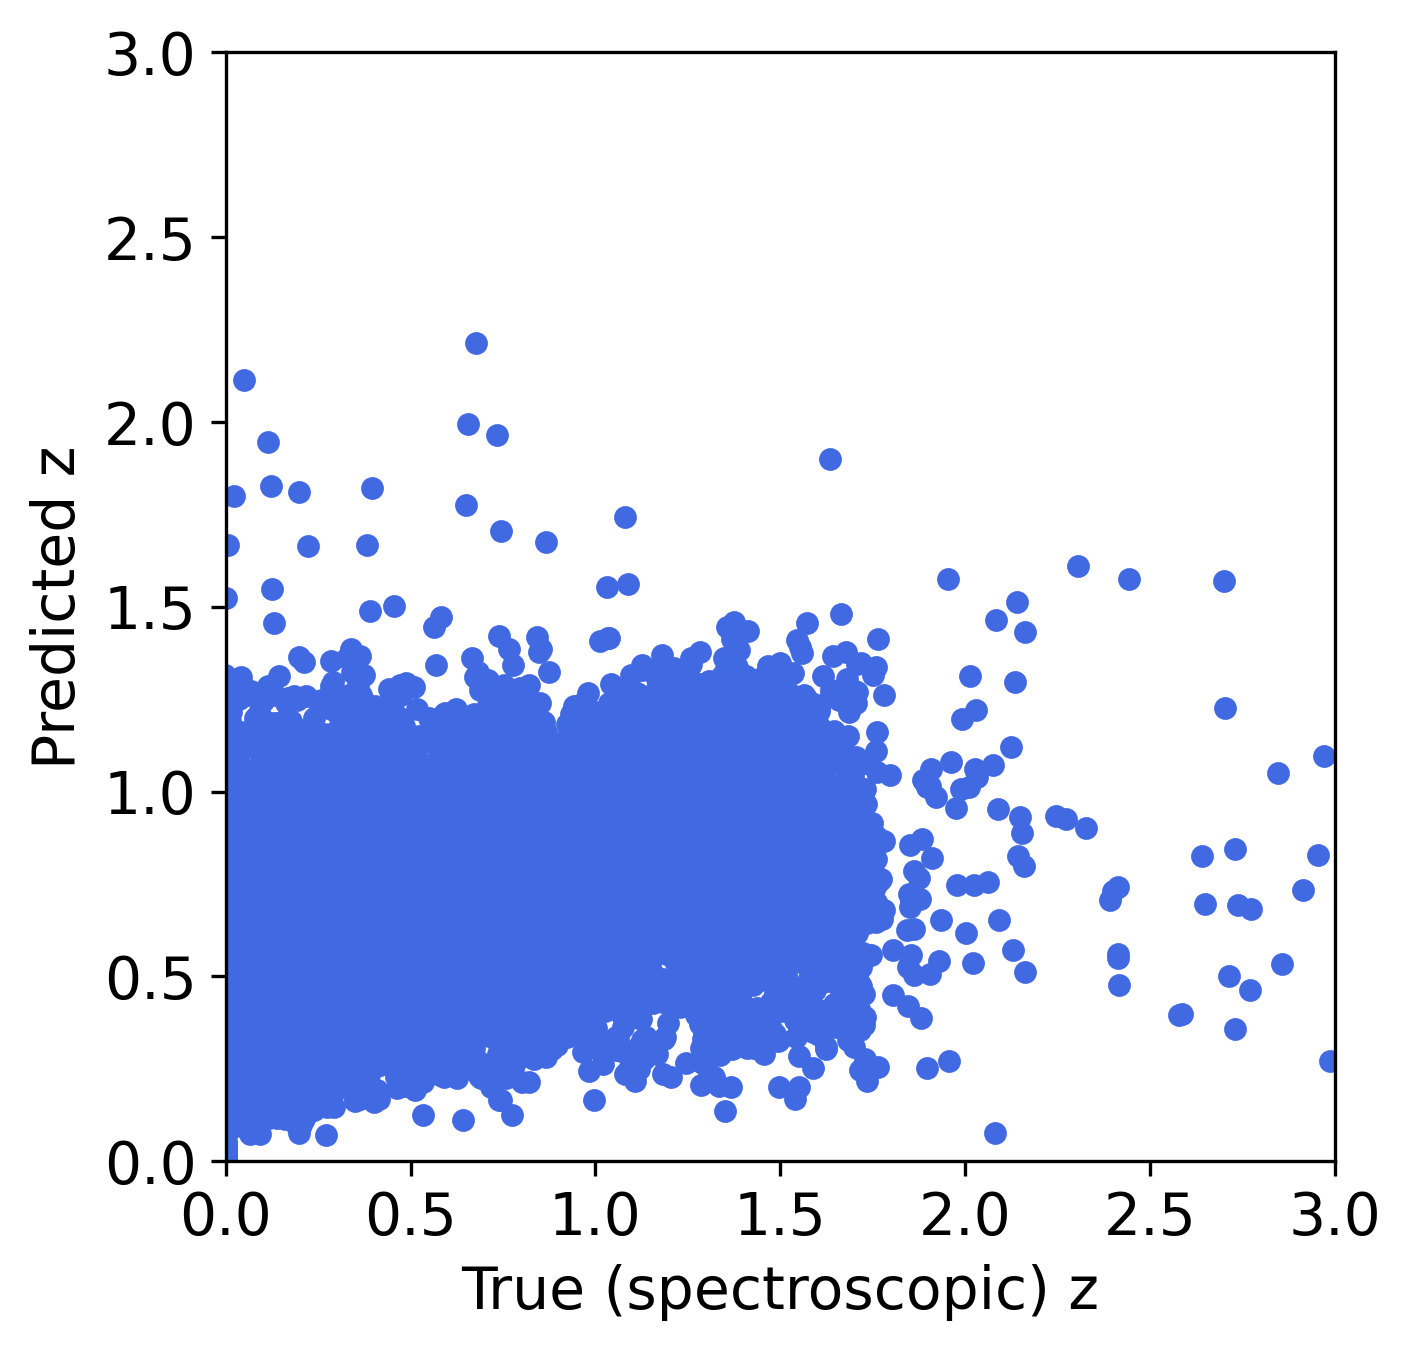

In [27]:
plt.scatter(target,ypred, s = 20, c = 'royalblue')
plt.xlabel('True (spectroscopic) z', fontsize=14)
plt.ylabel('Predicted z',fontsize=14)
plt.axis('square')
plt.xlim(0,3)
plt.ylim(0,3)

### Se parece al resultado del paper??

R: No, en el que se acaba de hacer se puede notar una dispersión mucho mayor con respecto al del paper, hay muchos outliers y no muestra una relación 1 es a 1

También es interesante observar la distribución de los valores predichos, para ver cómo siempre tienden a producir una distribución más estrecha. 

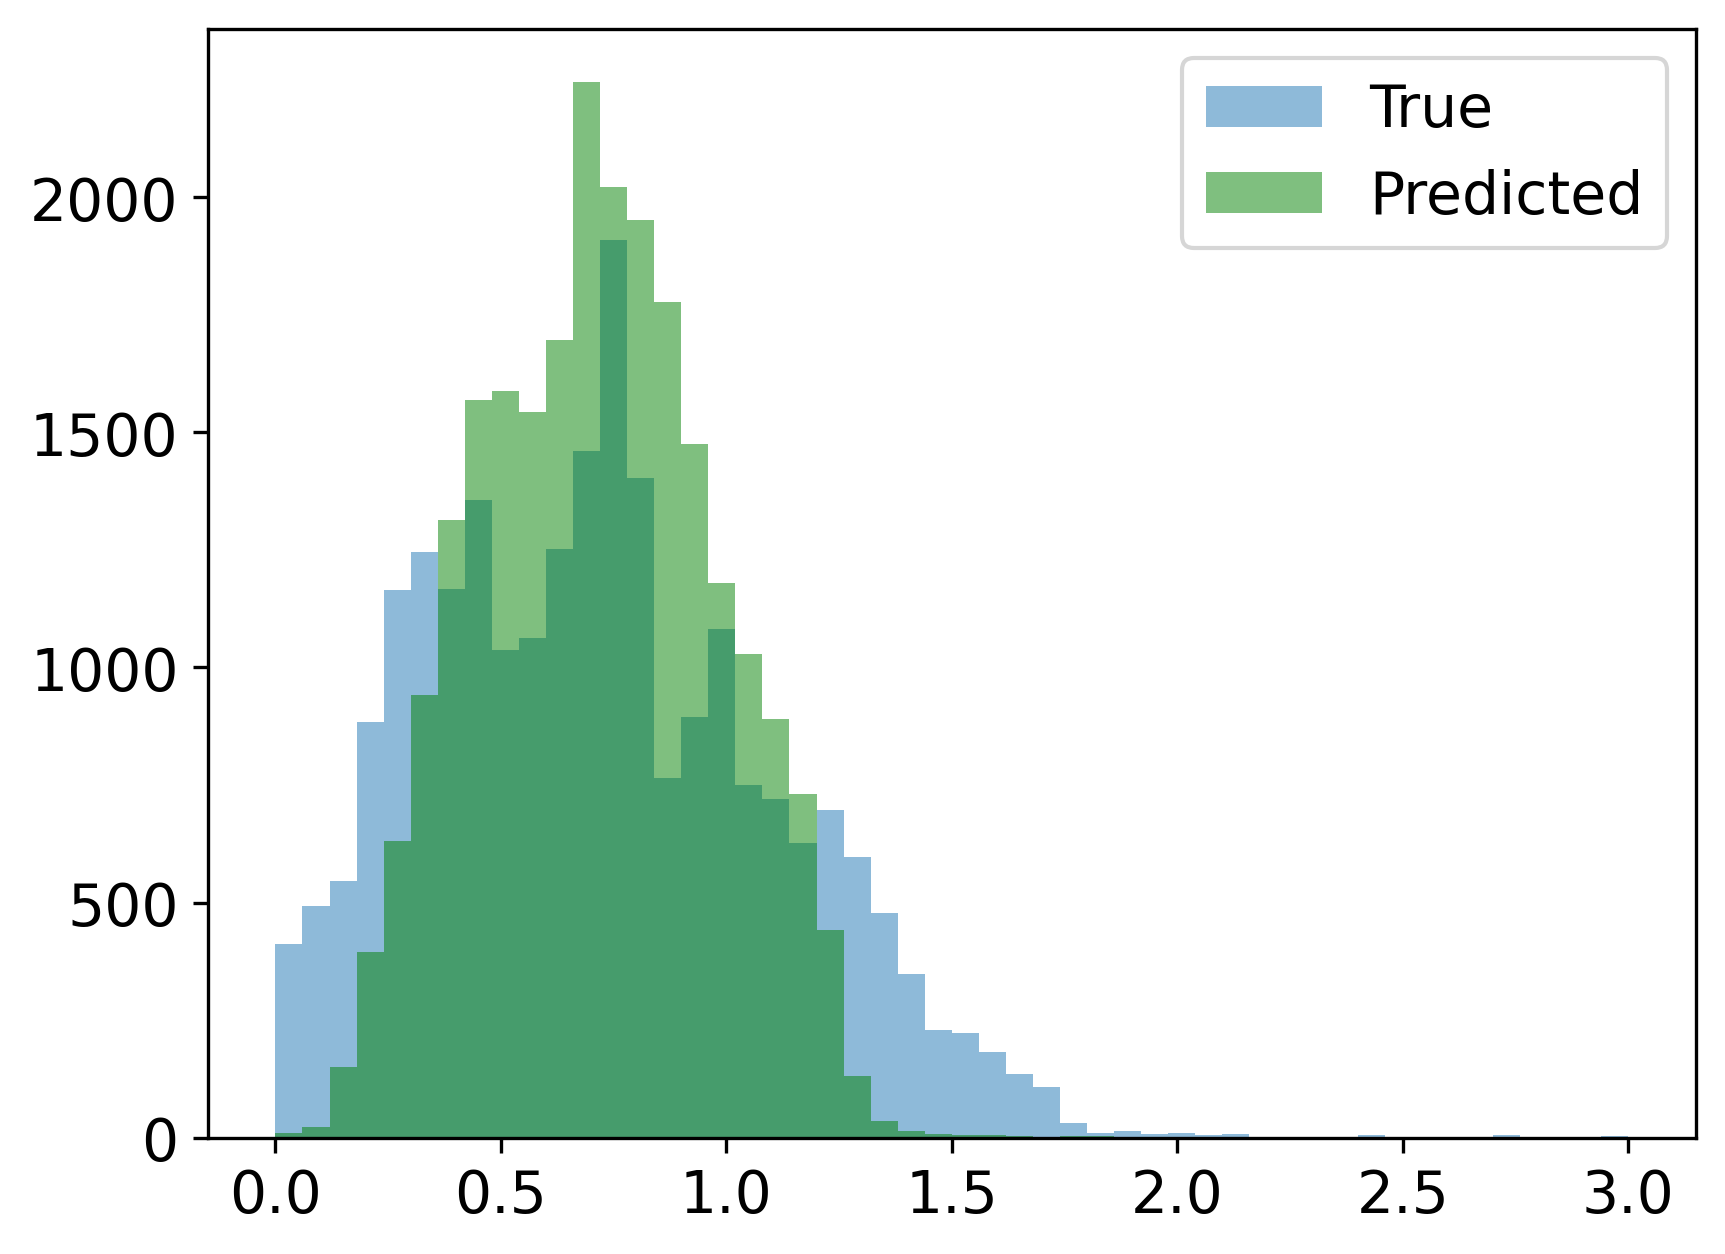

In [28]:
plt.hist(target,bins=50,density=False,alpha=0.5, range = (0,3), label = 'True');
plt.hist(ypred,bins=50,density=False,alpha=0.5, range = (0,3), color = 'g', label = 'Predicted');
plt.legend(fontsize=14);

Ahora calcule las métricas del paper, fracción de outliers $eta$ y $\sigma_{NMAD}$ y compare con los resultados del paper

In [29]:
def metricas(z_true, z_pred):
    dz = z_pred - z_true
    eta = np.mean(np.abs(dz) > 0.15 * (1 + z_true))
    nmad = 1.48 * np.median(np.abs(dz) / (1 + z_true))
    return eta, nmad

In [30]:
eta, nmad = metricas(target, ypred)
print('Fracción de outliers eta = %.3f' % eta)

Fracción de outliers eta = 0.258


y NMAD

In [31]:
print('sigma_NMAD = %.4f' % nmad)

sigma_NMAD = 0.0749


### Optimicemos los hiperparámetros del modelo

Seleccionemos un subsample de los datos para que se reduzcan los tiempos computacionales

In [32]:
np.random.seed(20)
sel = np.random.choice(range(len(ypred)), 5000, replace = False) #sample sin reemplazo 

In [33]:
len(np.unique(sel))

5000

Y creamos nuestro nuevo dataset más pequeño

In [34]:
seld = features.loc[sel,:]
selt = target[sel]

Chequeemos que la performance del modelo usando todo el set de datos es similar a los obtenidos con nuestro set de datos menor, lo que significaria que el cambio en el tamaño del set no afectará el proceso de optimización

In [35]:
littlescores = cross_validate(model,seld,selt, cv = KFold(n_splits=5, shuffle=True, random_state=10), return_train_score=True)

In [36]:
littlescores['test_score'].mean(), littlescores['train_score'].mean()

(np.float64(0.27762715338769406), np.float64(0.8763722031531694))

### Estamos listos para optimizar hiperparámetros...cuáles escogemos?



#### Parámetros de árbol

- El número mínimo de instancias en un nodo hoja

- El número mínimo de instancias requerido en un nodo de división

- La profundidad máxima del árbol

- El criterio elegido para decidir si una división "vale la pena", expresado en términos de ganancia de información

#### Parámetros de randomización



- El número de $k < n$ características que se utilizan para construir los árboles

- El resampling (bootstrap) del conjunto de datos (Verdadero o Falso)

#### Parámetros del bosque

El número de árboles en el bosque (n_estimators) se puede ajustar, con el entendimiento general de que más árboles son mejores, pero en algún punto el rendimiento se estabiliza, por lo que se puede encontrar el equilibrio entre tener más árboles y un menor tiempo de ejecución.

Podemos visualizarlos así

In [37]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Implemente `GridSearchCV` o `RandomizedGridSearch()` para los siguientes parámetros y compare los resultados del mejor modelo con los del paper 

- min_impurity_decrease 

- number of trees

- max_leaf_nodes

- min_samples_split

- max_features

In [38]:
%%time
#Toma algunos minutos
parameters = {'min_impurity_decrease':[0.1, 0.5, 0.0], \
              'max_features':[None,4,2], 'n_estimators':[50, 100, 200], 'min_samples_split': [10,20,100], 
              'max_leaf_nodes':[None, 100, 200]}
#... implemente el resto

model = GridSearchCV(RandomForestRegressor(), parameters, cv=cv, verbose=2,
                     n_jobs=-1, return_train_score=True)
model.fit(seld, selt)
print('Best params, best score:', '%.4f' % model.best_score_, model.best_params_)

Fitting 5 folds for each of 243 candidates, totalling 1215 fits


[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=50; total time=   0.2s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=100; total time=   0.4s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=100; total time=   0.4s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=20, n_estimators=50; total time=   0.2s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=50; total time=   0.2s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=50; total time=   0.2s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=20, n_estimators=50; total time=   0.4s
[CV] END max_features=None, max_leaf_nodes=None, min_impurit

Guardamos el resultado en un dataframe y buscamos el mejor modelo 

In [39]:
scores = pd.DataFrame(model.cv_results_)
scoresCV = scores[['params','mean_test_score','std_test_score','mean_train_score']].sort_values(by = 'mean_test_score', \
                                                    ascending = False)


In [40]:
scoresCV

,params,mean_test_score,std_test_score,mean_train_score
104,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 2...",0.300805,0.029836,0.652676
103,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 2...",0.298658,0.030438,0.651001
101,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.297940,0.033717,0.753311
182,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.296972,0.030956,0.725782
158,"{'max_features': 4, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.0, 'min_samples_split': 20...",0.296570,0.029812,0.627666
...,...,...,...,...
54,"{'max_features': None, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.1, 'min_samples_split':...",-0.000301,0.000219,-0.000011
60,"{'max_features': None, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.1, 'min_samples_split':...",-0.000302,0.000221,-0.000012
117,"{'max_features': 4, 'max_leaf_nodes': 100, 'min_impurity_decrease': 0.5, 'min_samples_split': 10...",-0.000311,0.000173,-0.000009
87,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.1, 'min_samples_split': 1...",-0.000312,0.000216,-0.000009


### Mejoran los scores?

R: No realmente el mejor R2=0.30, casi no cambia, optimizar los hiperparametros no resolvió el problema.

### Un poco de ingeniería de características

Miraremos otras columnas disponibles del set de datos (Tabla 6 del paper)

In [41]:
mags = df[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor','subaru_source','cfhtls_source','zquality']]



In [42]:
mags.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor,subaru_source,cfhtls_source,zquality
0,23.543491,23.430495,23.100311,22.768970,22.223810,21.926356,1,1,2
1,30.848978,28.989668,19.027422,99.000000,99.000000,18.811085,1,1,4
2,24.324670,24.273606,24.150319,23.446252,23.574236,-99.000000,-99,1,1
3,99.000000,24.804309,23.636544,23.009222,22.689591,22.535600,1,1,1
4,24.362068,24.136913,23.490342,22.777181,22.319676,22.100980,1,1,4


In [43]:
mags.shape

(23822, 9)

In [44]:
#zquality - solo usa objetos con medición de redshift de buena calidad

mags = mags[mags['zquality'] >= 3]

mags.shape

(16857, 9)

In [45]:
#selecciona objetos con datos del catálogo cfhtls deep photometric data

mags = mags[mags['cfhtls_source'] == 0]

mags.shape

(10671, 9)

In [46]:
mags.describe()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor,subaru_source,cfhtls_source,zquality
count,10671.000000,10671.000000,10671.000000,10671.000000,10671.000000,10671.000000,10671.000000,10671.0,10671.000000
mean,24.956618,24.401613,23.773396,23.269147,23.015069,-26.690387,-39.851748,0.0,3.868054
std,7.805795,7.758577,7.796453,7.851747,7.880700,59.420143,48.595520,0.0,0.338448
min,17.226409,16.367331,15.657234,15.303275,15.007688,-99.000000,-99.000000,0.0,3.000000
25%,23.580188,23.111998,22.457752,21.871468,21.563535,-99.000000,-99.000000,0.0,4.000000
50%,24.193906,23.807774,23.255549,22.717913,22.444333,20.927547,0.000000,0.0,4.000000
75%,24.800523,24.335112,23.782535,23.309253,23.074766,22.529628,0.000000,0.0,4.000000
max,99.000000,99.000000,99.000000,99.000000,99.000000,99.000000,1.000000,0.0,4.000000


Las mediciones no disponibles están marcadas por -99 o 99 (mientras que los valores típicos están alrededor de 20-25). También eliminamos los datos con mediciones faltantes.

In [47]:
mags = mags[mags > -10].dropna()

In [48]:
mags.shape

(6371, 9)

In [49]:
mags = mags[mags < 90].dropna()

In [50]:
mags.shape

(6307, 9)

Tenemos un dataset con las 6 features originales y 6307 objetos

In [51]:
sel_features = mags[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor']]
sel_features.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor
1251,24.244393,23.979583,23.522136,22.911041,22.525773,22.329098
1253,24.489104,23.916151,22.923651,21.873752,21.306495,21.251440
1261,24.873959,22.973893,21.465850,20.788420,20.462283,20.413696
1271,24.529042,24.338631,23.891189,23.206102,22.989344,23.112382
1272,23.641180,23.387447,22.975301,22.235199,21.809658,21.559483


Selección del vector de target

In [52]:
sel_target = target[sel_features.index]

**Vuelva a correr el modelo benchmark con estas nuevas características y compare con los resultados anteriores. Puede optimizar nuevamente los hiperparámetros para mejorar aún más el modelo. Compare los valores predichos con los valores reales y concluya respecto a los resultados con la nueva selección de datos.** 

In [54]:
scores_new = cross_validate(RandomForestRegressor(), sel_features, sel_target, cv=cv,
                            return_train_score=True, n_jobs=-1)
print('Train R2: %.3f ± %.3f' % (scores_new['train_score'].mean(), scores_new['train_score'].std()))
print('Test R2: %.3f ± %.3f' % (scores_new['test_score'].mean(), scores_new['test_score'].std()))

Train R2: 0.964 ± 0.004
Test R2: 0.745 ± 0.106


In [55]:
gs_new = GridSearchCV(RandomForestRegressor(), parameters, cv=cv, n_jobs=-1)
gs_new.fit(sel_features, sel_target)
print(gs_new.best_score_, gs_new.best_params_)

0.7406368216830006 {'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 10, 'n_estimators': 200}


(0.0, 3.0)

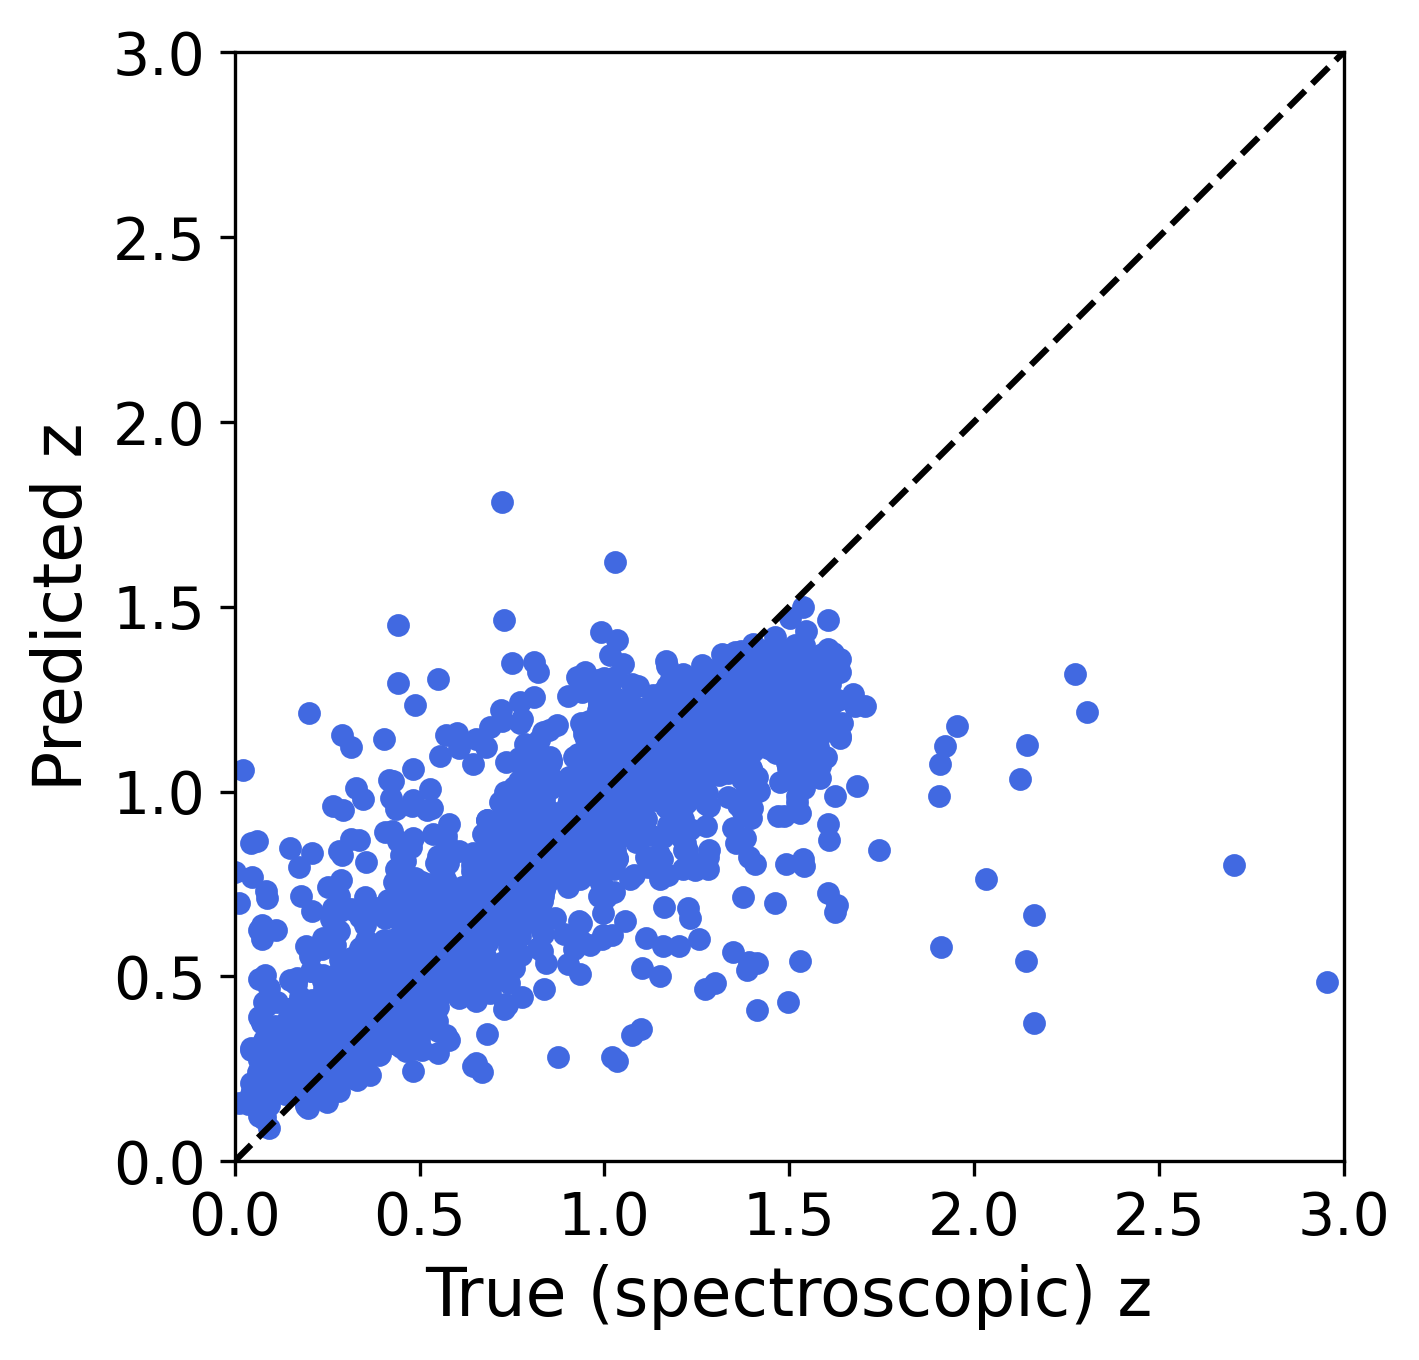

In [56]:
ypred_new = cross_val_predict(RandomForestRegressor(**gs_new.best_params_), sel_features, sel_target, cv=cv, n_jobs=-1)
plt.scatter(sel_target, ypred_new, s=20, c='royalblue')
plt.plot([0, 3], [0, 3], 'k--')
plt.xlabel('True (spectroscopic) z'); plt.ylabel('Predicted z')
plt.axis('square'); plt.xlim(0, 3); plt.ylim(0, 3)

In [57]:
eta_new, nmad_new = metricas(sel_target, ypred_new)
print('eta = %.3f, sigma_NMAD = %.4f' % (eta_new, nmad_new))

eta = 0.060, sigma_NMAD = 0.0400


### Conclusion: Cómo se compara nuestro modelo con el resultado del paper? 

R: El R2 de prueba subió a 0.74 eta bajó a 0.3 y sigma_NMAD a 0.04, esto se acerca mucho más al paper ya que los valores de eta y sigma_NMAD son muy parecidos a la FIG 5 de este mismo. La importancia estaba en la calidad de los datos mas que en el ajuste en sí.

Revise la sección 7 del paper. Podemos mejorar nuestro modelo aún más? Implemente un nuevo modelo con la mejora identificada



Train R2: 0.971   Test R2: 0.810
eta = 0.036, sigma_NMAD = 0.0164


(0.0, 3.0)

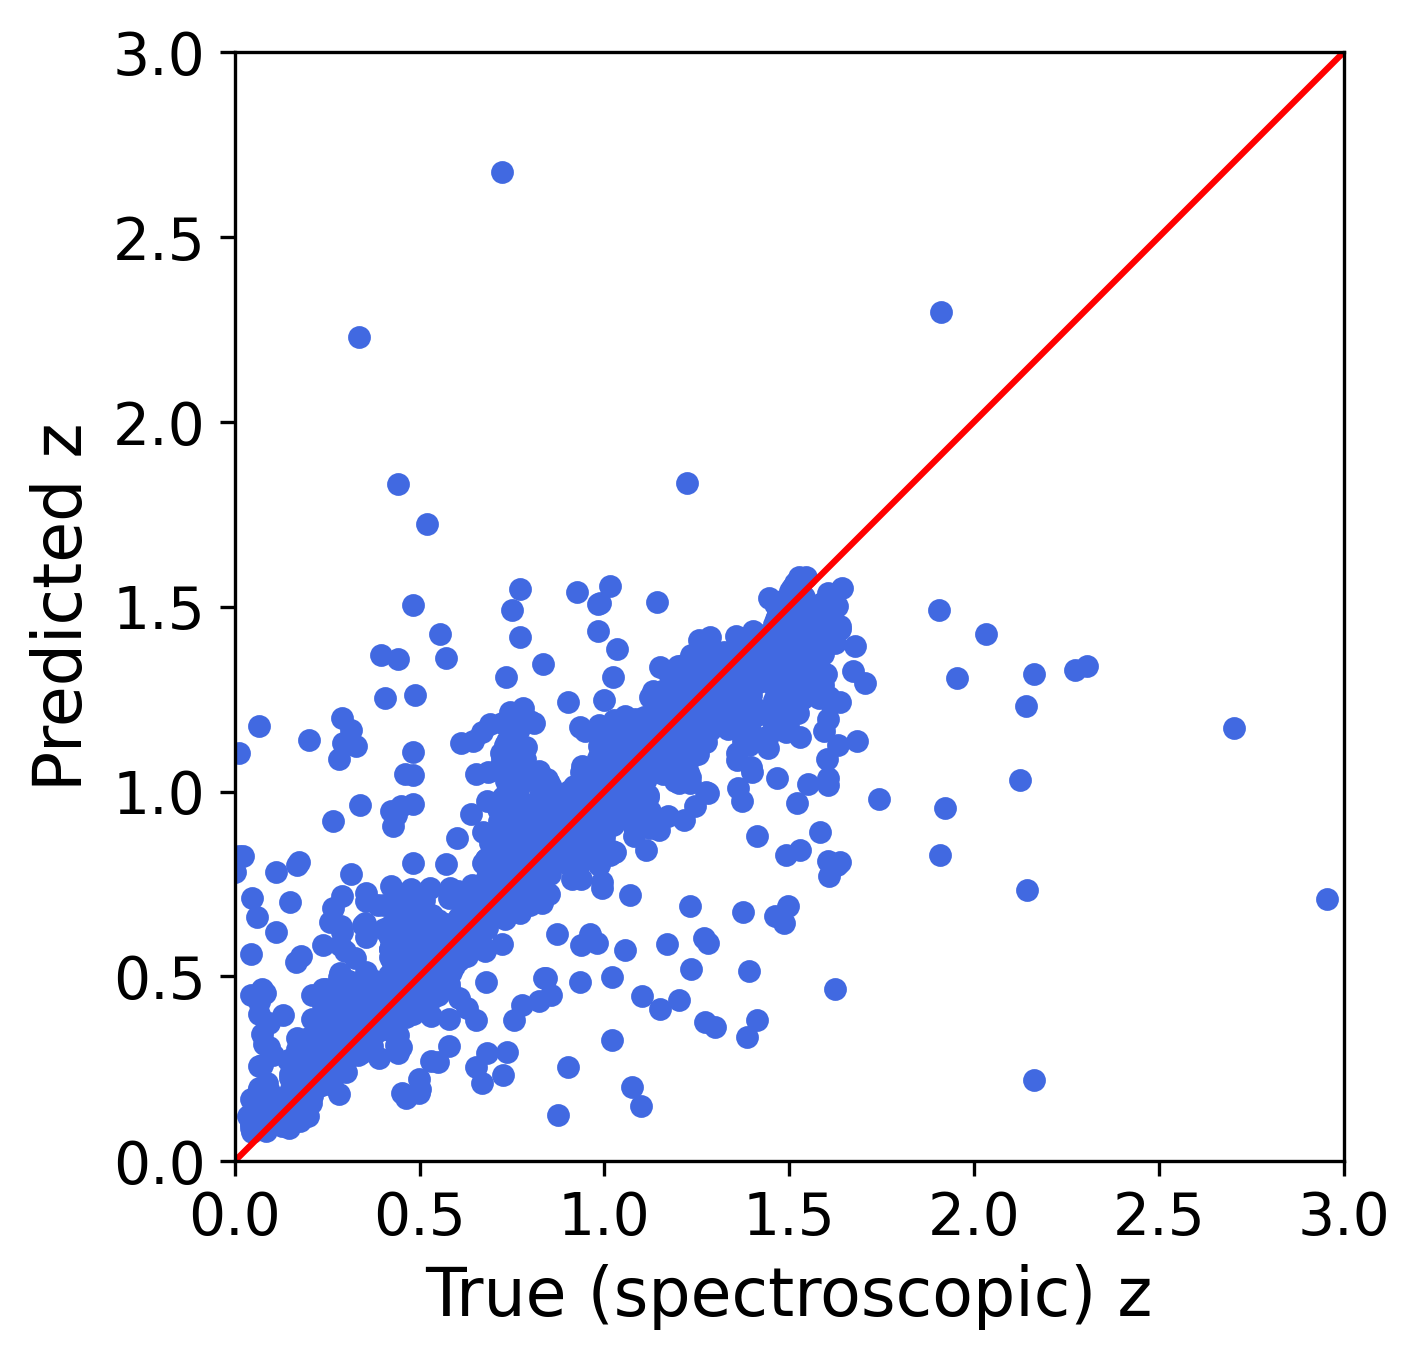

In [58]:
colors = pd.DataFrame({
    'u-g': sel_features['u_apercor'] - sel_features['g_apercor'],
    'g-r': sel_features['g_apercor'] - sel_features['r_apercor'],
    'r-i': sel_features['r_apercor'] - sel_features['i_apercor'],
    'i-z': sel_features['i_apercor'] - sel_features['z_apercor'],
    'z-y': sel_features['z_apercor'] - sel_features['y_apercor'],
    'i':   sel_features['i_apercor']})

scores_col = cross_validate(RandomForestRegressor(), colors, sel_target, cv=cv,
                            return_train_score=True, n_jobs=-1)
print('Train R2: %.3f   Test R2: %.3f' % (scores_col['train_score'].mean(), scores_col['test_score'].mean()))

ypred_col = cross_val_predict(RandomForestRegressor(), colors, sel_target, cv=cv, n_jobs=-1)
eta_col, nmad_col = metricas(sel_target, ypred_col)
print('eta = %.3f, sigma_NMAD = %.4f' % (eta_col, nmad_col))

plt.scatter(sel_target, ypred_col, s=20, c='royalblue')
plt.plot([0, 3], [0, 3], 'r-')
plt.xlabel('True (spectroscopic) z'); plt.ylabel('Predicted z')
plt.axis('square'); plt.xlim(0, 3); plt.ylim(0, 3)

Bueno, siguiendo la sección 7, se usaron los 5 colores más la magnitud i. El R2 de prueba subió a 0.81, eta bajó a 0.036 y sigma_NMAD a 0.016. Esto es mejor que lo anterior y se compara muy bien con la figura 6 del paper. Por lo que en conclusión elegir bien las caracteristicas es muy importante y es más importante que optimizar los hiperparametros.